# IS 4487 Assignment 6: Data Cleaning with Airbnb Listings

In this assignment, you will:
- Load a raw Airbnb listings dataset
- Identify and resolve missing or inconsistent data
- Decide what data to drop, keep, or clean
- Save a clean dataset to use in Assignment 7

## Why This Matters

Data cleaning is one of the most important steps in any analysis — but it's often the least visible. Airbnb hosts, managers, and policy teams rely on clean data to make decisions. This assignment gives you experience cleaning raw data and justifying your choices so others can understand your process.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_06_data_cleaning.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

📌 The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.


## 1. Choose a City & Upload Your Dataset

📥 Follow these steps:

1. Go to: [https://insideairbnb.com/get-the-data/](https://insideairbnb.com/get-the-data/)
2. Choose a city you’re interested in.
3. Download the file named: **`listings.csv.gz`** under that city.
4. In your notebook:
   - Open the left sidebar
   - Click the folder icon 📁
   - Click the upload icon ⬆️ and choose your `listings.csv.gz` file
5. Use the file path `/content/listings.csv.gz` when loading your data.
6. Import standard libraries (`pandas`, `numpy`, `seaborn`, `matplotlib`)


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Boston listings, Inside Airbnb scrape from 2026-09-19
df = pd.read_csv("/content/listings.csv.gz")
print(df.shape)
df.head()

(4368, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,3781,https://www.airbnb.com/rooms/3781,20260919134146,2026-09-20,NaN,Harborside-Walk to subway,Fully separate apartment in a two apartment bu...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,4804,...,4.96,4.85,4.89,NaN,NaN,1,1,0,0,0.20
1,5506,https://www.airbnb.com/rooms/5506,20260919134146,2026-09-20,NaN,** Fort Hill Inn Private! Minutes to center!**,**THE BEST Value in BOSTON!!*** PRIVATE GUEST ...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,8229,...,4.89,4.59,4.78,STR-490093,NaN,11,11,0,0,0.68
2,6695,https://www.airbnb.com/rooms/6695,20260919134146,2026-09-20,NaN,"Fort Hill Inn *Sunny* 1 bedroom, condo duplex","Comfortable, Fully Equipped private apartment...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,8229,...,4.94,4.55,4.73,STR-491702,NaN,11,11,0,0,0.69
3,10811,https://www.airbnb.com/rooms/10811,20260919134146,2026-09-20,previous scrape,Bostons Best Rentals -Studio Prestigious Back Bay,Bostons Best Rentals offers a Stunning Back Ba...,NaN,https://a0.muscache.com/pictures/45735/27548f7...,38997,...,4.00,5.00,4.67,NaN,NaN,10,10,0,0,0.07
4,10813,https://www.airbnb.com/rooms/10813,20260919134146,2026-09-20,NaN,The Back Bay Nook -Brownstone in Prestigious ...,Stunning Back Bay furnished studio apartment. ...,NaN,https://a0.muscache.com/pictures/20b5b9c9-e1f4...,38997,...,5.00,5.00,4.86,NaN,NaN,10,10,0,0,0.08


## 2. Explore Missing Values

### Business framing:

Stakeholders don’t like surprises in the data. Missing values can break dashboards, confuse pricing models, or create blind spots for host managers.

### Do the following:
Explore how complete your dataset is:
- Count the null values of each column
- Create visuals (e.g. heatmaps, boxplots, bar charts, etc) to help show what columns are missing values
- Keep in mind which column(s) are missing too much data, you will delete these in the next step

In [3]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_table = pd.DataFrame({'missing': missing, 'pct_missing': missing_pct})
missing_table = missing_table[missing_table['missing'] > 0].sort_values('missing', ascending=False)
missing_table

,missing,pct_missing
neighborhood_overview,4368,100.0
host_since,4368,100.0
host_acceptance_rate,4368,100.0
host_response_rate,4368,100.0
host_response_time,4368,100.0
host_total_listings_count,4368,100.0
host_neighbourhood,4368,100.0
host_verifications,4368,100.0
host_thumbnail_url,4368,100.0
calendar_updated,4368,100.0


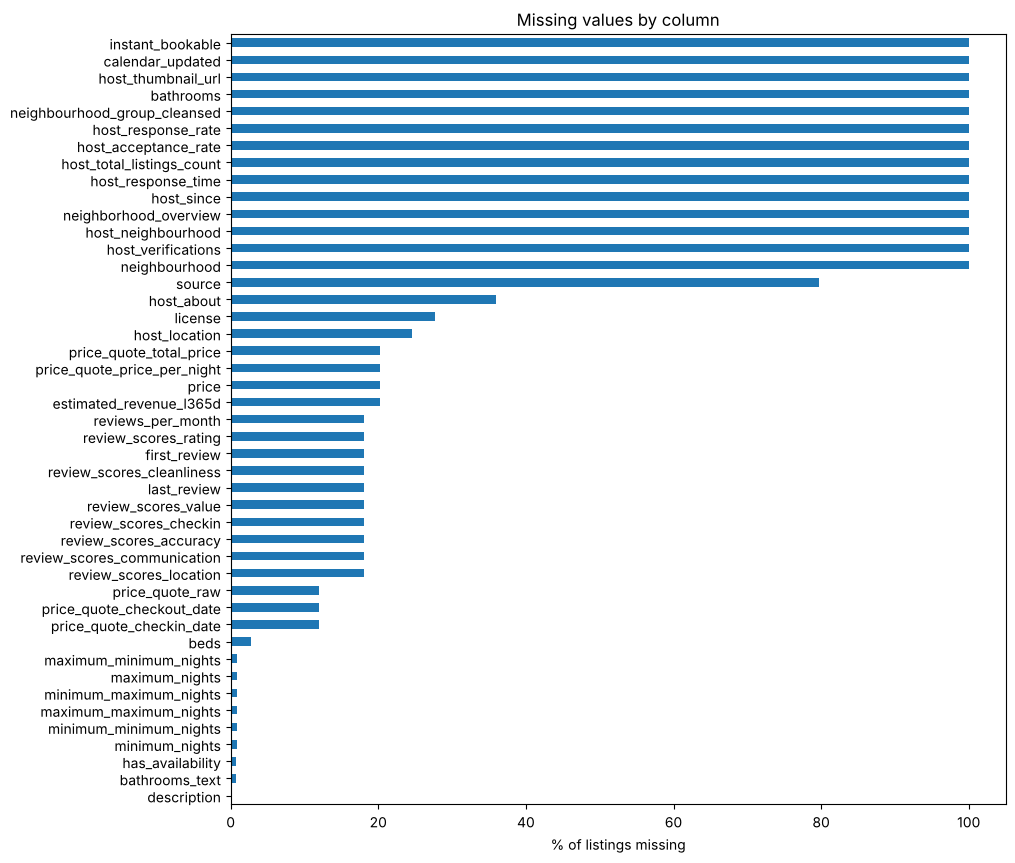

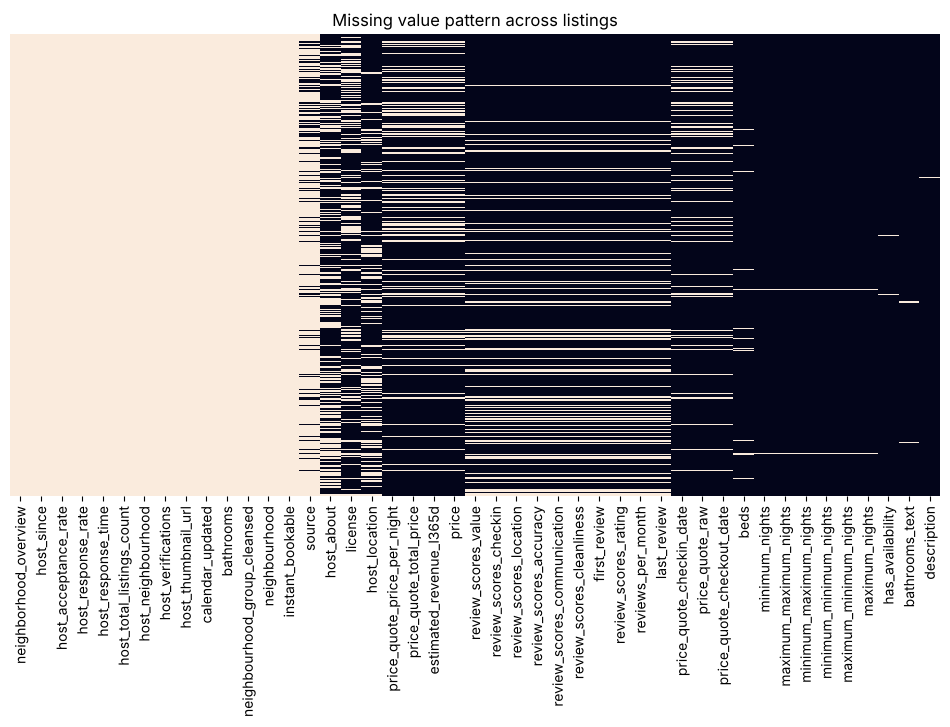

In [4]:
# Bar chart: % missing for every column that has gaps
missing_table['pct_missing'].sort_values().plot(kind='barh', figsize=(10, 10))
plt.xlabel('% of listings missing')
plt.title('Missing values by column')
plt.show()

# Heatmap: where the gaps sit row by row (light = missing)
plt.figure(figsize=(12, 6))
sns.heatmap(df[missing_table.index].isnull(), cbar=False, yticklabels=False)
plt.title('Missing value pattern across listings')
plt.show()

### Reflection:
1. What are the top 3 columns with the most missing values?
2. Which ones are likely to create business issues?
3. Which could be safely ignored or dropped?

### ✍️ Your Response: 🔧
1. Fourteen columns are tied at 100% missing – fields like `host_response_rate`, `host_since`, and `neighborhood_overview` came through completely blank in this scrape. Among columns that actually have data, the top three are `source` (80%), `host_about` (36%), and `license` (28%).

2. `price` is the big one at 20% missing – any pricing model or revenue estimate loses one in five listings, and `estimated_revenue_l365d` is blank on the same rows. The review scores (18% missing) matter for ranking listing quality, and `license` matters for checking which listings are registered with the city. The fully empty host response columns are also a blind spot for anyone managing host performance.

3. The 100% empty columns can go since there's nothing in them. `source` (just scrape metadata) and `host_about` (a free-text host bio) can also be ignored for most business questions.


## 3. Drop Columns That Aren’t Useful

### Business framing:  

Not every column adds value. Analysts often remove columns that are too empty, irrelevant, or repetitive — especially when preparing data for others.

### Do the following:
Make a decision:

- Choose 2–4 columns to drop from your dataset
- Document your reasons for each one
- Confirm they're gone with `.head()` or `.info()`

In [5]:
# neighbourhood: 100% empty, and neighbourhood_cleansed already has the neighborhood
# bathrooms: 100% empty, and bathrooms_text already has the bathroom count
# source: 80% empty, and it only says whether the row came from a previous scrape
# price_quote_raw: raw JSON blob that repeats what's already in the price_quote_* columns
df = df.drop(columns=['neighbourhood', 'bathrooms', 'source', 'price_quote_raw'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4368 entries, 0 to 4367
Data columns (total 86 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            4368 non-null   int64  
 1   listing_url                                   4368 non-null   object 
 2   scrape_id                                     4368 non-null   int64  
 3   last_scraped                                  4368 non-null   object 
 4   name                                          4368 non-null   object 
 5   description                                   4361 non-null   object 
 6   neighborhood_overview                         0 non-null      float64
 7   picture_url                                   4368 non-null   object 
 8   host_id                                       4368 non-null   int64  
 9   host_url                                      4368 non-null   o

### Reflection: 
1. Which columns did you drop?
2. Why were they not useful from a business perspective?
3. What could go wrong if you left them in?

### ✍️ Your Response: 🔧
1. `neighbourhood`, `bathrooms`, `source`, and `price_quote_raw`.

2. `neighbourhood` and `bathrooms` are completely empty, and the same info already lives in `neighbourhood_cleansed` and `bathrooms_text`. `source` only says whether a row was carried over from a previous scrape, which doesn't help a pricing or host decision. `price_quote_raw` is a raw JSON blob – unreadable for a business user and it repeats what's in the other `price_quote_` columns. (The other 10 fully empty columns get dropped right before export in Part 7.)

3. Someone could grab the wrong column – pull `neighbourhood` instead of `neighbourhood_cleansed` and get nothing back. Extra empty or duplicate columns also make the file bigger and harder to read, and a long JSON column can break things when the CSV is opened in Excel or Tableau.


## 4. Fill or Fix Values in Key Columns

### Business framing:  

Let’s say your manager wants to see a map of listings with prices and review scores. If key fields are blank, the map won’t work. But not all missing values should be filled the same way.

### Do the following:
- Choose 2 columns with missing values
- Use a strategy to fill or flag those values
  - (e.g., median, “unknown”, forward-fill, or a placeholder)
- Explain what you did and why

In [6]:
# reviews_per_month is only blank when a listing has 0 reviews, so blank means 0
print("Blank reviews_per_month with 0 reviews:", (df['reviews_per_month'].isnull() & (df['number_of_reviews'] == 0)).sum())
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# host_location is free text the host chose not to give, so flag it instead of guessing
df['host_location'] = df['host_location'].fillna('Unknown')

df[['reviews_per_month', 'host_location']].isnull().sum()

Blank reviews_per_month with 0 reviews: 789


reviews_per_month    0
host_location        0
dtype: int64

### Reflection:
1. What two columns did you clean?
2. What method did you use for each, and why?
3. What risks are there in how you filled the data?

### ✍️ Your Response: 🔧
1. `reviews_per_month` and `host_location`.

2. `reviews_per_month` – filled with 0. I checked that all 789 blanks are listings with 0 reviews, so the real value is 0, not unknown. `host_location` – filled with "Unknown". It's text the host chose not to give and there's no fair way to guess it, so a placeholder keeps the rows and makes the gap visible.

3. A 0 makes a brand-new listing look the same as one nobody books. "Unknown" becomes its own category, so anyone grouping by location has to remember it isn't a real place. I purposely didn't fill `price` or the review scores with a median – that would make up prices and make unreviewed listings look average.


## 5. Convert and Clean Data Types

### Business framing:  

Sometimes columns that look like numbers are actually stored as text — which breaks calculations and slows down analysis. Common examples are price columns with dollar signs or availability stored as strings.

### Do the following:
- Identify one column with the wrong data type
- Clean and convert it into a usable format (e.g., from string to number)
- Check your work by summarizing or plotting the cleaned column

Before: object ['$111.62', '$189.00', '$254.38']
After: float64


count    3486.000000
mean      315.160186
std       279.658190
min        30.440000
25%       150.105000
50%       253.330000
75%       397.000000
max      4815.000000
Name: price, dtype: float64

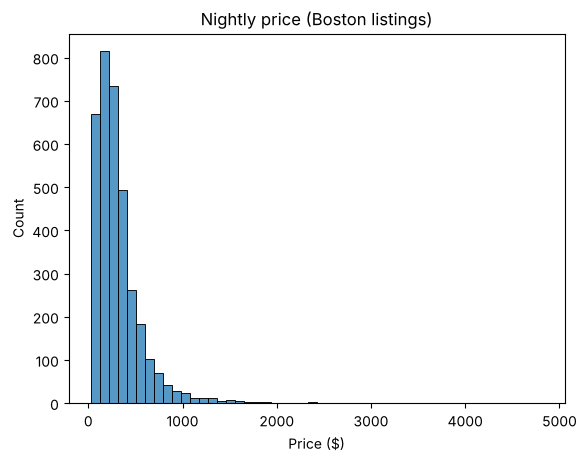

In [7]:
# price is stored as text like "$1,234.00", so strip "$" and "," and convert to a number
print("Before:", df['price'].dtype, df['price'].dropna().head(3).tolist())
df['price'] = df['price'].str.replace('[$,]', '', regex=True).astype(float)
print("After:", df['price'].dtype)

display(df['price'].describe())
sns.histplot(df['price'], bins=50)
plt.title('Nightly price (Boston listings)')
plt.xlabel('Price ($)')
plt.show()

### Reflection: :
1. What column did you fix?
2. What cleaning steps did you apply?
3. How does this help prepare the data for later use?

### ✍️ Your Response: 🔧
1. `price`.

2. It was stored as text like "$1,234.00". I stripped the "$" and commas with `str.replace` and converted it to a float. Blanks stay blank (NaN) instead of being filled. The summary and histogram check out: median of about $253/night, most listings under $1k, and a long right tail up to $4,815.

3. Price is now a number, so it can be averaged, filtered, and used in Assignment 7 (like price per bedroom or price by neighborhood). As text, pandas couldn't even take a mean of it.


## 6. Remove Duplicate Records

### Business framing:  

If a listing appears twice, it could inflate revenue estimates or confuse users. Airbnb needs each listing to be unique and accurate.

### Do the following:
- Check for rows that are exact duplicates 
- If your data has an ID column and each ID is supposed to unique, then make sure there are no duplicate IDs 
- Remove duplicates if found 

In [8]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate listing IDs:", df['id'].duplicated().sum())

Exact duplicate rows: 0
Duplicate listing IDs: 0


### Reflection:
1. Did you find duplicates?
2. How did you decide what to drop or keep?
3. Why are duplicates risky for Airbnb teams?

### ✍️ Your Response: 🔧 🔧
1. No – 0 exact duplicate rows and 0 repeated listing IDs across 4,368 listings.

2. Each `id` is supposed to be one listing, so I checked both full-row duplicates and repeated IDs. Both came back 0, so there was nothing to drop and every row stayed.

3. A doubled listing inflates supply counts and revenue estimates for a neighborhood, skews average price, and can show up twice on a map or in search.


## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 7**, where you'll perform data transformation techniques.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_6.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”) 
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP 
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP 

```





In [9]:
# 10 more columns came in with no data at all, so drop them before sharing the file
df = df.dropna(axis=1, how='all')

df.to_csv("cleaned_airbnb_data_6.csv", index=False)
print(df.shape)

(4368, 74)


## 8. Final Reflection

You’ve just cleaned a real-world Airbnb dataset — the kind of work that happens every day in analyst and data science roles.

Before you move on to data transformation in Assignment 7, take a few moments to reflect on the decisions you made and what you learned.

### Reflection:
1. Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts? 
2. Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data? (e.x. dropping a column full of null values because it has no useful information) 
3. What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
4. If you had more time, what would you explore or clean further?
5. How does this relate to your customized learning outcome you created in canvas?


Write your response clearly in full sentences. No more than a few sentences required per response.


### ✍️ Your Response: 🔧

1. Part 2 (missing values) was the hardest, and it was the application more than the coding. Fourteen columns were completely empty, and the real work was figuring out which blanks meant something (a listing with no reviews) versus data that just wasn't collected.

2. `reviews_per_month` is a good example of fixing data. Every blank lined up with a listing that had 0 reviews, so filling with 0 was accurate, not a guess. I made the opposite call on `price`: about half the listings missing a price (447 of 882) have zero availability for the next year, so they aren't really bookable, and inventing a price for them would mislead.

3. A pricing analyst can now compare nightly prices across neighborhoods and room types, since price is numeric and the unbookable listings are easy to filter out. Hosts could use that to benchmark their own rates.

4. I'd turn `amenities` (a list stored as text) into yes/no columns, convert the review dates to real dates, change `host_is_superhost` from "t"/"f" to true/false, and look closer at the very high prices (like the $4,815/night listing).

5. My first learning outcome is about producing a clean, analysis-ready dataset from messy sources to support a healthcare M&A sale process. This is the same set of judgment calls – what's blank versus truly zero, which fields duplicate others, and what to flag instead of fill – that I'd face cleaning up a target company's data before building comps or a data pack.


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_06_data_cleaning.ipynb"